In [1]:
# Jupyter notebook test flag (set to False for full production runs)
# DEBUG = globals().get("DEBUG", False)

%matplotlib widget
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import mars_currents.config as cfg
from mars_currents.grid import load_grid
from mars_currents.generic import angle_difference

In [2]:
loaded_grids = {}
grid_colors = {}

location = cfg.RESULTS
grids_to_load = [
    (
        "grid_dr0.04_dth10_dphi18__mag_mse_2014-10-11_2020-08-14_n15_all.pickle",
        "All_",
        "black",
    ),
    (
        "grid_dr0.04_dth10_dphi18__mag_mse_2014-10-11_2020-08-14_n15_NH.pickle",
        "NH_",
        "C0",
    ),
    (
        "grid_dr0.04_dth10_dphi18__mag_mse_2014-10-11_2020-08-14_n15_high_pdyn.pickle",
        "High_",
        "C3",
    ),
    (
        "grid_dr0.04_dth10_dphi18__mag_mse_2014-10-11_2020-08-14_n15_low_pdyn.pickle",
        "Low_",
        "C1",
    ),
]

for grid_pickle, global_prefix, color in grids_to_load:
    try:
        loaded_grids[global_prefix] = load_grid(
            load_from_file=True, file_path=location / grid_pickle
        )
        grid_colors[global_prefix] = color
    except Exception as e:
        print(f"Error loading {grid_pickle}: {e}")
        raise

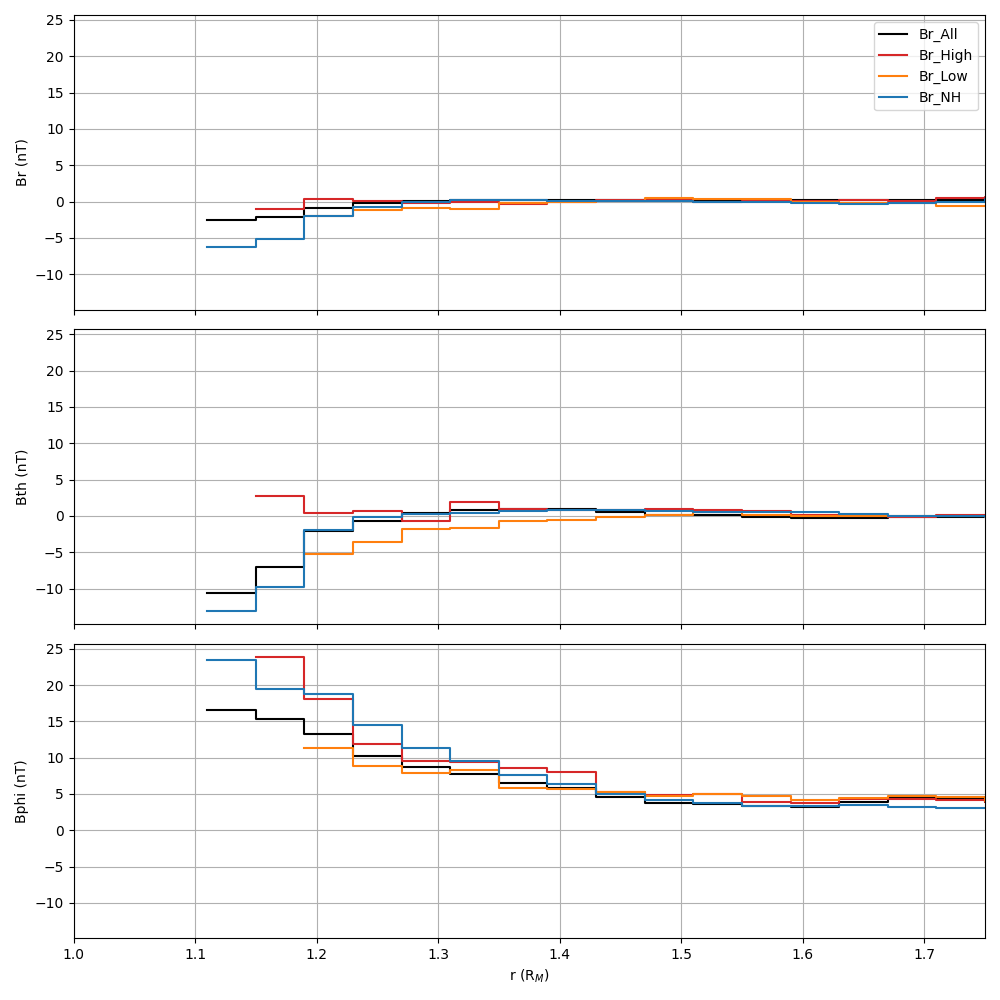

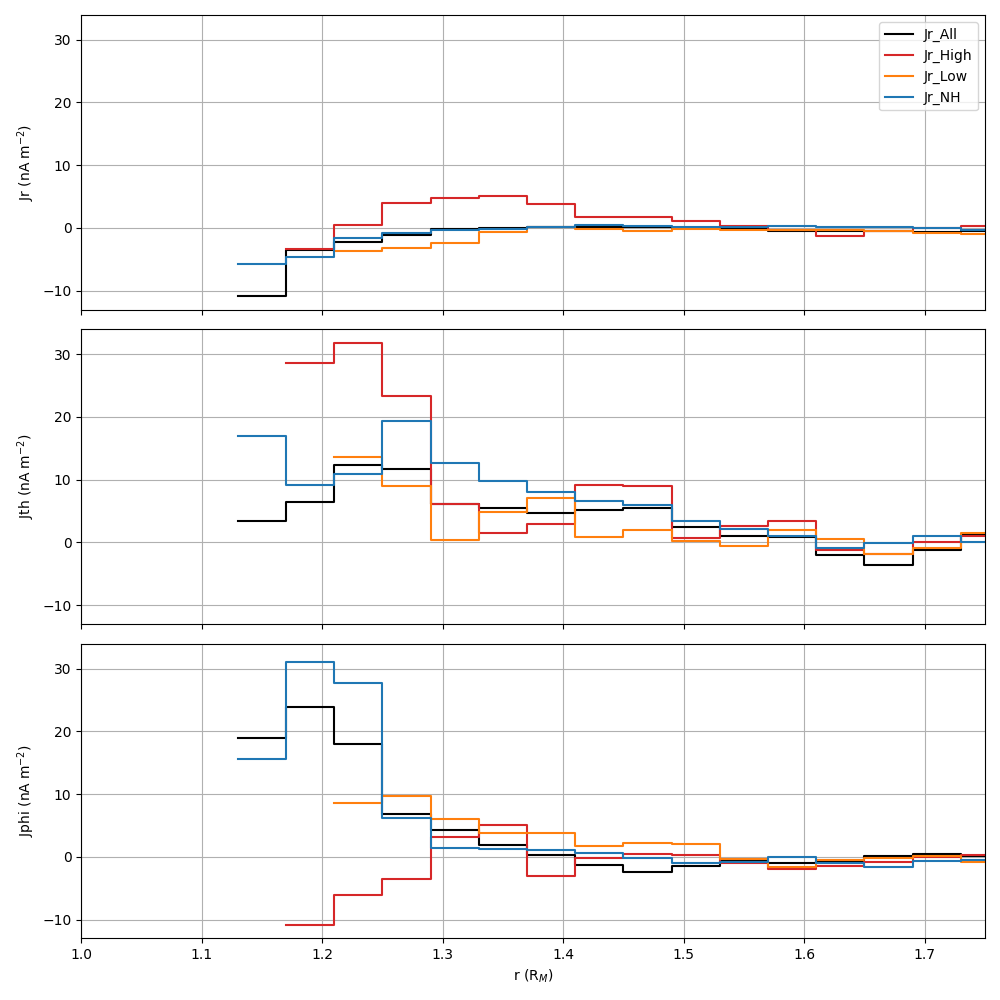

In [3]:
r_pos = np.arange(1.0, 3.0, 0.01)
theta_pos = np.zeros_like(r_pos) + np.pi / 2
phi_pos = np.zeros_like(r_pos)


# Extract magnetic field magnitude
def vector_processor(B_vector=None):
    shape = (3,)
    if B_vector is None:
        return np.zeros(shape) + np.nan
    out = np.array(B_vector)
    assert out.shape == shape, f"Expected shape {shape} but got {out.shape}"
    return out


# for prefix in ("All_", "High_", "Low_", "NH_"):
#     grid = loaded_grids[prefix]
#     b_values, (r_idx, th_idx, phi_idx), (r_c, th_c, phi_c), cells = grid.sample_fields(
#         r=r_pos,
#         theta=theta_pos,
#         phi=phi_pos,
#         field_name="B_mse_mean",
#         processor=vector_processor,
#         return_indices=True,
#         return_centers=True,
#         return_cells=True,
#     )

#     plt.sca(axs[0])
#     pfx =  "_" + prefix.strip("_")
#     plt.plot(r_pos, b_values[:, 0], label="Br" + pfx, color=grid_colors[prefix])

#     plt.sca(axs[1])
#     plt.plot(r_pos, b_values[:, 1], label="Btheta"+pfx, color=grid_colors[prefix])
#     plt.sca(axs[2])

#     plt.plot(r_pos, b_values[:, 2], label="Bphi"+pfx, color=grid_colors[prefix])
#     # plt.plot(r_pos, b_r_values, label="Br2")

dr = -0.02
for quant in ("B", "J"):
    dr += 0.02  # for vis
    fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True, sharey=True)
    for prefix in ("All_", "High_", "Low_", "NH_"):
        grid = loaded_grids[prefix]
        kwargs = dict(
            r=r_pos,
            theta=theta_pos,
            phi=phi_pos,
        )

        # for i, key in enumerate(["Br", "Bth", "Bphi"]):
        for i, key in enumerate(["r", "th", "phi"]):
            key = quant + key
            b_values = grid.sample_fields(field_name=key, **kwargs)

            plt.sca(axs[i])
            pfx = "_" + prefix.strip("_")
            plt.plot(
                r_pos + dr,
                b_values,
                label=key + pfx,
                color=grid_colors[prefix],
                ds="steps",
            )

    unit = " (nT)"
    if quant == "J":
        unit = r" (nA$\;$m$^{-2}$)"
    plt.xlabel("r (R$_M$)")
    axs[0].set_ylabel(quant + "r" + unit)
    axs[1].set_ylabel(quant + "th" + unit)
    axs[2].set_ylabel(quant + "phi" + unit)
    axs[0].legend()
    axs[0].set_xlim(1.0, 1.75)
    for i in range(3):
        axs[i].grid()
    plt.tight_layout()
# plt.show()

<>:56: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\p'
/var/folders/4g/vr81rlmd0xqcpxx6c6ththv80000gp/T/ipykernel_64112/2675271913.py:56: SyntaxWarning: invalid escape sequence '\p'
  fancy = dict(r=r"r", th=r"\theta", phi="\phi")


[0.         0.17453293 0.34906585 0.52359878 0.6981317  0.87266463
 1.04719755 1.22173048 1.3962634  1.57079633 1.74532925 1.91986218
 2.0943951  2.26892803 2.44346095 2.61799388 2.7925268  2.96705973
 3.31612558 3.4906585  3.66519143 3.83972435 4.01425728 4.1887902
 4.36332313 4.53785606 4.71238898 4.88692191 5.06145483 5.23598776
 5.41052068 5.58505361 5.75958653 5.93411946 6.10865238 6.28318531]
[0.         0.17453293 0.34906585 0.52359878 0.6981317  0.87266463
 1.04719755 1.22173048 1.3962634  1.57079633 1.74532925 1.91986218
 2.0943951  2.26892803 2.44346095 2.61799388 2.7925268  2.96705973]
[-3.14159265 -2.82743339 -2.51327412 -2.19911486 -1.88495559 -1.57079633
 -1.25663706 -0.9424778  -0.62831853 -0.31415927  0.          0.31415927
  0.62831853  0.9424778   1.25663706  1.57079633  1.88495559  2.19911486
  2.51327412  2.82743339]
1.7493243751346426
Total Phi Current 115.13 [kA] (+ve: 296.20, -ve: -181.07), STD_ABS 0.33


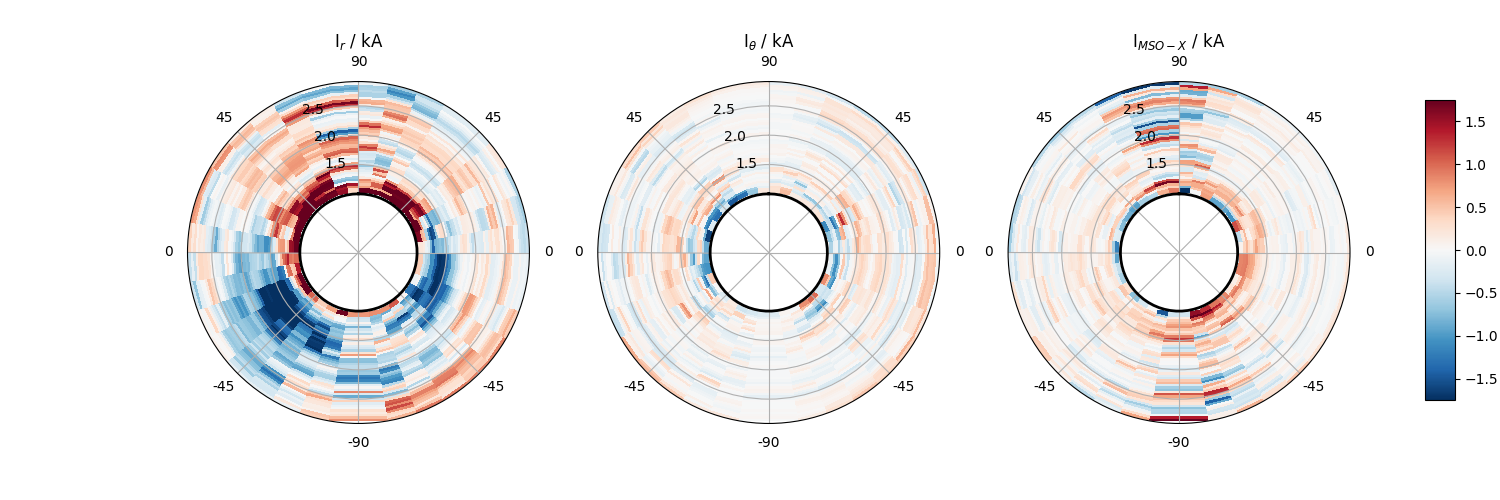

In [4]:
# Polar plot of Phi Current density at the terminator.
grid = loaded_grids["All_"]

theta_values = grid.th_bins
phi_values = grid.phi_bins
r_values = grid.r_bins
# r_values = r_values[r_values < 1.7]
theta_values = np.array(theta_values)
wrapped_theta_values = np.concat((theta_values, 2 * np.pi - theta_values[::-1]))
print(wrapped_theta_values)
print(theta_values)
print(phi_values)
img = np.zeros((wrapped_theta_values.shape[0], r_values.shape[0], 3))

ones = np.ones_like(r_values)

for j, d in enumerate(("r", "th", "phi")):
    for i, th in enumerate(wrapped_theta_values):
        _th = th
        _phi = -np.pi / 2.0
        flip_phi = False

        # Going round the circle.
        if _th > np.pi:
            _th = 2 * np.pi - _th
            _phi = np.pi / 2.0
            flip_phi = True
        vals = grid.sample_fields(
            r=r_values, theta=ones * _th, phi=ones * _phi, field_name="I" + d
        )

        # Flip sign of _phi component if we are in the dusk side, so that
        # we show a value "into/outof" the plane
        if d == "phi" and flip_phi:
            vals = -vals

        img[i, :, j] = vals

fig, axs = plt.subplots(
    1, 3, figsize=[15, 5], subplot_kw=dict(projection="polar", theta_offset=np.pi / 2)
)

img = img / 1e12  # kA

vrange = np.nanmax(np.abs(img))
vrange = np.nanpercentile(np.abs(img), 98)
print(vrange)


ticks = np.arange(0.0, 2 * np.pi, np.pi / 4)


def tick_f(x):
    _x = np.rad2deg(x)
    _x = 90 - _x
    if _x < -90:
        _x = -180 - _x
    return _x


unit_circle = np.linspace(0.0, 2 * np.pi, 64)

fancy = dict(r=r"r", th=r"\theta", phi="\phi")
for j, d in enumerate(("r", "th", "phi")):
    plt.sca(axs[j])
    plt.pcolormesh(
        wrapped_theta_values,
        r_values,
        img[:-1, :-1, j].T,
        cmap="RdBu_r",
        vmin=-vrange,
        vmax=vrange,
    )

    axs[j].set_xticks(ticks, [f"{int(tick_f(v))}" for v in ticks])
    axs[j].set_title(rf"I$_{fancy[d]}$ / kA")

    rticks = axs[j].get_yticks()
    axs[j].set_rticks([r for r in rticks if r > 1.0])

    axs[j].plot(unit_circle, np.ones_like(unit_circle), "k-", lw=2.0)
    axs[j].set_rlim(0.0, r_values[-1])

    if d == "phi":
        axs[j].set_title(r"I$_{MSO-X}$ / kA")

        curr = img[:, :, j].flatten()
        curr = curr[np.isfinite(curr)]
        inx = curr > 0.0
        print(
            f"Total Phi Current {np.sum(curr):.2f} [kA] "
            f"(+ve: {np.sum(curr[inx]):.2f}, "
            f"-ve: {np.sum(curr[~inx]):.2f}), "
            f"STD_ABS {np.std(np.abs(curr)):.2f}"
        )


plt.colorbar(cax=fig.add_axes([0.95, 0.2, 0.02, 0.6]))
plt.show()
plt.savefig("TerminatorPlane.pdf")